# Gabarito — Triângulos Retângulos

Este notebook traz a resolução comentada dos exercícios de [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb).

⚠️ **Antes de olhar aqui:** tente resolver os exercícios sozinho no notebook original e use as células de verificação (`assert`) para conferir sua resposta. Volte a este gabarito só depois de tentar — ou se travar de verdade em algum passo.

In [1]:
# Imports necessários para os exercícios abaixo
import math
from math import gcd

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas do notebook principal (reconstruídas aqui).

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


def lados(t) -> tuple[float, float, float]:
    """Medidas (a, b, c) dos lados do triângulo t = (A, B, C), na convenção de 0404a: a = BC é oposto a A,
    b = CA é oposto a B e c = AB é oposto a C."""
    A, B, C = t
    return math.dist(B, C), math.dist(C, A), math.dist(A, B)


def angulos(t) -> tuple[float, float, float]:
    """Medidas, em graus, dos ângulos internos (Â, B̂, Ĉ) do triângulo t = (A, B, C)."""
    A, B, C = t
    return medir_angulo(A, B, C), medir_angulo(B, C, A), medir_angulo(C, A, B)


def triangulo_por_lados(a: float, b: float, c: float):
    """Triângulo (A, B, C) com BC = a, CA = b e AB = c: A na origem, B sobre o eixo x e C no cruzamento das
    circunferências λ(A, b) e λ(B, a) (0415a). Devolve None se as medidas não formam triângulo (0404a)."""
    if not abs(b - c) < a < b + c:
        return None
    x = (b**2 + c**2 - a**2) / (2 * c)
    y = math.sqrt(b**2 - x**2)
    return [np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([x, y])]


def criterios_semelhanca(t1, t2) -> list[str]:
    """Lista dos critérios de semelhança ("AA", "LAL", "LLL") satisfeitos pelos triângulos t1 = (A, B, C) e
    t2 = (A', B', C'), com a correspondência dada pela ORDEM dos vértices (A↔A', B↔B', C↔C') (0415a)."""
    angulos_iguais = [math.isclose(x, y, abs_tol=1e-6) for x, y in zip(angulos(t1), angulos(t2))]
    razoes = [y / x for x, y in zip(lados(t1), lados(t2))]  # razoes[i]: lado oposto ao vértice i
    criterios = []
    if sum(angulos_iguais) >= 2:
        criterios.append("AA")
    for i in range(3):
        j, m = [x for x in range(3) if x != i]
        if angulos_iguais[i] and iguais(razoes[j], razoes[m]):
            criterios.append("LAL")
            break
    if iguais(razoes[0], razoes[1]) and iguais(razoes[1], razoes[2]):
        criterios.append("LLL")
    return criterios


def pe_da_altura(vertice, P, Q) -> np.ndarray:
    """Pé da altura traçada de `vertice` até a reta PQ: a projeção ortogonal do vértice sobre essa reta (0407a e
    0410a). Em coordenadas, H = P + ((V − P)·(Q − P) / |Q − P|²)·(Q − P)."""
    V, P, Q = (np.asarray(X, dtype=float) for X in (vertice, P, Q))
    u = Q - P
    return P + np.dot(V - P, u) / np.dot(u, u) * u


def distancia_ponto_reta(X, P, Q) -> float:
    """Distância do ponto X à reta PQ: a medida de X até o pé da perpendicular (0407a)."""
    return math.dist(X, pe_da_altura(X, P, Q))


def baricentro(A, B, C) -> np.ndarray:
    """Baricentro G: a média das coordenadas dos três vértices (0410a)."""
    return (np.asarray(A, dtype=float) + np.asarray(B, dtype=float) + np.asarray(C, dtype=float)) / 3


def incentro(A, B, C) -> np.ndarray:
    """Incentro I: a média dos vértices ponderada pelos lados opostos, I = (a·A + b·B + c·C) / (a + b + c) (0410a)."""
    a, b, c = lados([A, B, C])
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    return (a * A + b * B + c * C) / (a + b + c)


def circuncentro(A, B, C) -> np.ndarray:
    """Circuncentro: o cruzamento das mediatrizes de AB e de BC, as perpendiculares aos lados pelos pontos
    médios (0407a e 0410a)."""
    return cruzamento(ponto_medio(A, B), direcao_de(A, B) + 90, ponto_medio(B, C), direcao_de(B, C) + 90)


# Ferramentas novas deste notebook
# Notação fixa: a = BC (hipotenusa), b = CA e c = AB (catetos), h = AH (altura relativa à hipotenusa),
# m = BH (projeção de c) e n = HC (projeção de b). Cada cateto e a SUA projeção têm sempre a mesma cor.
COR_HIPOTENUSA = COR_AVISO  # a: amarelo
COR_CATETO_B = COR_DESTAQUE  # b e a sua projeção n: verde
COR_CATETO_C = COR_EXTRA  # c e a sua projeção m: roxo
COR_ALTURA = "#D08770"  # h: laranja
COR_TRIANGULO = COR_PONTO  # preenchimento dos triângulos
COR_CIRCULO = COR_SECUNDARIA  # circunferências


def triangulo_retangulo(a: float, posicao: float):
    """Triângulo ABC retângulo em A, com a hipotenusa BC = a sobre o eixo x (B = (0, 0) e C = (a, 0)) e o vértice
    A na semicircunferência de diâmetro BC, na direção `posicao` (em graus, entre 0° e 180°) vista do centro.
    Todo ponto dessa semicircunferência enxerga BC sob um ângulo reto (0413a)."""
    B, C = np.array([0.0, 0.0]), np.array([float(a), 0.0])
    A = ponto_medio(B, C) + (a / 2) * direcao(posicao)
    return A, B, C


def elementos(A, B, C) -> dict:
    """Elementos do triângulo ABC retângulo em A, na notação fixa do notebook: a = BC, b = CA, c = AB, o pé H da
    altura relativa à hipotenusa, h = AH, m = BH (projeção de c) e n = HC (projeção de b)."""
    H = pe_da_altura(A, B, C)
    return {"a": math.dist(B, C), "b": math.dist(C, A), "c": math.dist(A, B), "H": H,
            "h": math.dist(A, H), "m": math.dist(B, H), "n": math.dist(H, C)}


def desenhar_quadrado_no_lado(ax, P, Q, longe_de, cor: str, opacidade: float = 0.3, quadricular: bool = False,
                              rotulo: str | None = None, tamanho: int = 12) -> list[np.ndarray]:
    """Desenha o quadrado construído sobre o lado PQ, do lado oposto ao ponto `longe_de`, e devolve os seus
    vértices. Com `quadricular=True`, divide o quadrado em quadradinhos de lado 1 (para contar a área)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = Q - P
    normal = np.array([-u[1], u[0]])  # u girado de 90°: tem o mesmo tamanho do lado
    if np.dot(np.asarray(longe_de, dtype=float) - P, normal) > 0:
        normal = -normal
    vertices = [P, Q, Q + normal, P + normal]
    ax.add_patch(Polygon(vertices, closed=True, facecolor=cor, alpha=opacidade, edgecolor=cor, lw=2, zorder=1))
    lado = float(np.linalg.norm(u))
    if quadricular:
        for k in range(1, int(round(lado))):
            t = k / lado
            ax.plot(*zip(P + t * u, P + t * u + normal), color=cor, lw=0.8, alpha=0.6, zorder=2)
            ax.plot(*zip(P + t * normal, Q + t * normal), color=cor, lw=0.8, alpha=0.6, zorder=2)
    if rotulo:
        ax.text(*(P + u / 2 + normal / 2), rotulo, color=NORD_TEXTO, fontsize=tamanho, fontweight="bold",
                ha="center", va="center", zorder=7,
                bbox={"facecolor": NORD_FUNDO, "edgecolor": cor, "alpha": 0.85, "boxstyle": "round"})
    return vertices


def desenhar_elementos(ax, A, B, C, valores: bool = True, mostrar_altura: bool = True, tamanho: int = 12) -> None:
    """Figura padrão do triângulo ABC retângulo em A, com as cores fixas: a (amarelo), b e n (verde), c e m (roxo)
    e h (laranja). As projeções m e n aparecem como "réguas" logo abaixo da hipotenusa."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    el = elementos(A, B, C)
    a, H = el["a"], el["H"]
    u = (C - B) / a
    normal = np.array([-u[1], u[0]])
    if np.dot(A - B, normal) > 0:
        normal = -normal  # normal aponta para o lado oposto ao vértice A
    centro = (A + B + C) / 3

    def texto(nome: str, valor: float) -> str:
        return f"{nome} = {valor:.2f}" if valores else nome

    ax.add_patch(Polygon([A, B, C], closed=True, facecolor=COR_TRIANGULO, alpha=0.12, edgecolor="none", zorder=1))
    desenhar_segmento(ax, B, C, cor=COR_HIPOTENUSA, largura=3.5)
    desenhar_segmento(ax, C, A, cor=COR_CATETO_B, largura=3.5)
    desenhar_segmento(ax, A, B, cor=COR_CATETO_C, largura=3.5)
    desenhar_arco(ax, A, B, C, raio=0.09 * a, cor=NORD_TEXTO_SEC)
    rotular_segmento(ax, C, A, texto("b", el["b"]), cor=COR_CATETO_B, distancia=0.05 * a, longe_de=centro,
                     tamanho=tamanho)
    rotular_segmento(ax, A, B, texto("c", el["c"]), cor=COR_CATETO_C, distancia=0.05 * a, longe_de=centro,
                     tamanho=tamanho)
    ax.text(*(ponto_medio(B, C) + 0.2 * a * normal), texto("a", a), color=COR_HIPOTENUSA, fontsize=tamanho,
            fontweight="bold", ha="center", va="center")
    if mostrar_altura:
        desenhar_segmento(ax, A, H, cor=COR_ALTURA, largura=2.5, estilo="--")
        if el["m"] > 0.08 * a and el["n"] > 0.08 * a:
            desenhar_arco(ax, H, C, A, raio=0.06 * a, cor=COR_ALTURA)
        lado_livre = 1 if el["n"] >= el["m"] else -1  # escreve h do lado da projeção maior (mais espaço)
        ax.text(*(ponto_medio(A, H) + 0.02 * a * lado_livre * u), texto("h", el["h"]), color=COR_ALTURA,
                fontsize=tamanho, fontweight="bold", ha="left" if lado_livre * u[0] >= 0 else "right", va="center",
                zorder=7)
        deslocamento = 0.07 * a * normal
        for P, Q, cor, nome, valor in ((B, H, COR_CATETO_C, "m", el["m"]), (H, C, COR_CATETO_B, "n", el["n"])):
            if math.dist(P, Q) < 1e-9:
                continue
            desenhar_segmento(ax, P + deslocamento, Q + deslocamento, cor=cor, largura=3)
            for X in (P, Q):
                desenhar_segmento(ax, X + 0.6 * deslocamento, X + 1.4 * deslocamento, cor=cor, largura=1.5)
            ax.text(*(ponto_medio(P, Q) + 2.0 * deslocamento), texto(nome, valor), color=cor, fontsize=tamanho,
                    fontweight="bold", ha="center", va="center")
        desenhar_ponto(ax, H, cor=COR_ALTURA)
        ax.text(*(H - 0.05 * a * normal + 0.035 * a * u), "H", color=NORD_TEXTO, fontsize=tamanho + 1,
                fontweight="bold", ha="center", va="center", zorder=7)
    for X, nome in ((A, "A"), (B, "B"), (C, "C")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=0.055 * a, tamanho=tamanho + 1)


def classifica_por_lados(x: float, y: float, z: float) -> str:
    """Classifica o triângulo de lados x, y, z (em qualquer ordem) quanto aos ângulos, só pelos lados:
    'acutângulo', 'retângulo', 'obtusângulo' ou 'não forma triângulo'."""
    a, b, c = sorted((x, y, z), reverse=True)  # a é o MAIOR lado
    if c <= 0 or a >= b + c:  # desigualdade triangular (0404a)
        return "não forma triângulo"
    if math.isclose(a**2, b**2 + c**2, rel_tol=1e-9, abs_tol=1e-12):
        return "retângulo"
    return "acutângulo" if a**2 < b**2 + c**2 else "obtusângulo"


def eh_retangulo(x: float, y: float, z: float) -> bool:
    """True se x, y, z são os lados de um triângulo retângulo (recíproca de Pitágoras)."""
    return classifica_por_lados(x, y, z) == "retângulo"

## Básico

**Exercício 1.** Pitágoras direto: lados, ternos, diagonais e alturas.

In [2]:
# (a) Hipotenusa: a² = b² + c²
hipotenusa_ex1a = math.sqrt(9**2 + 12**2)  # √225 = 15 (é o terno 3–4–5 multiplicado por 3)

# (b) Cateto: c² = a² − b² (a hipotenusa é o 17, o MAIOR lado)
cateto_ex1b = math.sqrt(17**2 - 8**2)  # √(289 − 64) = √225 = 15

# (c) Para cada trio, o maior número faz o papel da hipotenusa
trios = [(6, 8, 10), (5, 12, 14), (9, 40, 41), (10, 24, 26), (7, 8, 11)]
ternos_ex1c = [t for t in trios if sorted(t)[2] ** 2 == sorted(t)[0] ** 2 + sorted(t)[1] ** 2]

# (d) Diagonais: ℓ√2 no quadrado e √(a² + b²) no retângulo
diagonal_quadrado_ex1d = 6 * math.sqrt(2)  # ≈ 8,485
diagonal_retangulo_ex1d = math.sqrt(5**2 + 12**2)  # 13 (terno 5–12–13)

# (e) Altura do equilátero: ℓ√3/2 (metade do equilátero é um 30°–60°–90° com x = 4)
altura_equilatero_ex1e = 8 * math.sqrt(3) / 2  # 4√3 ≈ 6,928

print(hipotenusa_ex1a, cateto_ex1b, ternos_ex1c, round(diagonal_quadrado_ex1d, 4), diagonal_retangulo_ex1d,
      round(altura_equilatero_ex1e, 4))
for t in trios:
    print(f"{t}: maior² = {max(t) ** 2},  soma dos outros² = {sum(x * x for x in t) - max(t) ** 2}")

15.0 15.0 [(6, 8, 10), (9, 40, 41), (10, 24, 26)] 8.4853 13.0 6.9282
(6, 8, 10): maior² = 100,  soma dos outros² = 100
(5, 12, 14): maior² = 196,  soma dos outros² = 169
(9, 40, 41): maior² = 1681,  soma dos outros² = 1681
(10, 24, 26): maior² = 676,  soma dos outros² = 676
(7, 8, 11): maior² = 121,  soma dos outros² = 113


Em (c), $(5, 12, 14)$ falha porque $14^2 = 196 \neq 169$, e $(7, 8, 11)$ porque $121 \neq 113$. Os outros três são múltiplos de ternos primitivos: $(6, 8, 10) = 2 \cdot (3, 4, 5)$, $(10, 24, 26) = 2 \cdot (5, 12, 13)$; e $(9, 40, 41)$ já é primitivo (Euclides com $p = 5$, $q = 4$).

**Exercício 2.** As relações métricas a partir de duas medidas.

In [3]:
# (a) m = 2, n = 8
m, n = 2, 8
h_ex2a = math.sqrt(m * n)  # h² = m·n = 16 → h = 4
a_ex2a = m + n  # 10
b_ex2a = math.sqrt(a_ex2a * n)  # b² = a·n = 80 (b é o cateto cuja projeção é n)
c_ex2a = math.sqrt(a_ex2a * m)  # c² = a·m = 20
print(f"(a) h = {h_ex2a:g}, a = {a_ex2a:g}, b = √80 ≈ {b_ex2a:.4f}, c = √20 ≈ {c_ex2a:.4f}")
print(f"    conferência: b² + c² = {b_ex2a**2 + c_ex2a**2:g} = a² = {a_ex2a**2:g}")

# (b) a = 25 e h = 12: m + n = 25 e m·n = 144. São as raízes de x² − 25x + 144 = 0 (soma e produto, 0109a)
delta = 25**2 - 4 * 144  # 625 − 576 = 49
projecoes_ex2b = ((25 - math.sqrt(delta)) / 2, (25 + math.sqrt(delta)) / 2)  # (9, 16)
print(f"(b) projeções: {projecoes_ex2b}")

# (c) c = 6 e b = 8: primeiro a hipotenusa, depois as outras relações
c, b = 6, 8
a = math.sqrt(b**2 + c**2)  # 10
h_ex2c = b * c / a  # b·c = a·h → h = 48/10 = 4,8
m_ex2c = c**2 / a  # c² = a·m → m = 36/10 = 3,6
n_ex2c = b**2 / a  # b² = a·n → n = 64/10 = 6,4
print(f"(c) a = {a:g}, h = {h_ex2c:g}, m = {m_ex2c:g}, n = {n_ex2c:g};  m + n = {m_ex2c + n_ex2c:g},  "
      f"m·n = {m_ex2c * n_ex2c:g} = h² = {h_ex2c**2:g}")

(a) h = 4, a = 10, b = √80 ≈ 8.9443, c = √20 ≈ 4.4721
    conferência: b² + c² = 100 = a² = 100
(b) projeções: (9.0, 16.0)
(c) a = 10, h = 4.8, m = 3.6, n = 6.4;  m + n = 10,  m·n = 23.04 = h² = 23.04


Em (c), as duas últimas contas conferem o resultado por outras relações: $m + n = a$ e $m \cdot n = h^2$. O cateto **menor** ($c = 6$) tem a projeção **menor** ($m = 3{,}6$): o cateto e a sua projeção andam juntos.

## Intermediário

**Exercício 3.** As funções da seção 2, escritas por você.

In [4]:
def classifica_por_lados_ex3(x: float, y: float, z: float) -> str:
    a, b, c = sorted((x, y, z), reverse=True)  # a = maior lado
    # 1º) a desigualdade triangular: o maior lado tem de ser MENOR que a soma dos outros dois
    if c <= 0 or a >= b + c:
        return "não forma triângulo"
    # 2º) compara a² com b² + c², com tolerância (0.3² + 0.4² não dá exatamente 0.5² no computador)
    if math.isclose(a**2, b**2 + c**2, rel_tol=1e-9, abs_tol=1e-12):
        return "retângulo"
    return "acutângulo" if a**2 < b**2 + c**2 else "obtusângulo"


def eh_retangulo_ex3(x: float, y: float, z: float) -> bool:
    return classifica_por_lados_ex3(x, y, z) == "retângulo"


def ternos_primitivos_ex3(limite: int) -> list[tuple[int, int, int]]:
    ternos = []
    p = 2
    while p * p + 1 <= limite:  # com q = 1, a hipotenusa p² + 1 já é a menor possível para esse p
        for q in range(1, p):
            hipotenusa = p * p + q * q
            if hipotenusa <= limite and gcd(p, q) == 1 and (p - q) % 2 == 1:
                x, y = p * p - q * q, 2 * p * q
                ternos.append((min(x, y), max(x, y), hipotenusa))
        p += 1
    return sorted(ternos)


print(classifica_por_lados_ex3(5, 13, 12), eh_retangulo_ex3(2, 3, 4), ternos_primitivos_ex3(30))
print("quantidade com hipotenusa até 1000:", len(ternos_primitivos_ex3(1000)))

retângulo False [(3, 4, 5), (5, 12, 13), (7, 24, 25), (8, 15, 17), (20, 21, 29)]
quantidade com hipotenusa até 1000: 158


Os dois cuidados que mais fazem errar: **testar a desigualdade triangular primeiro** (senão $(1, 2, 3)$ vira "obtusângulo") e **não comparar com `==`** (senão $(0{,}3;\ 0{,}4;\ 0{,}5)$ não é reconhecido como retângulo). Nos ternos, a condição "paridades diferentes" elimina, por exemplo, $(p, q) = (3, 1)$, que daria $(6, 8, 10)$; e a condição "coprimos" elimina casos como $(p, q) = (9, 6)$: $9 - 6 = 3$ é ímpar, mas $\gcd(9, 6) = 3$, e o terno seria $(45, 108, 117) = 9 \cdot (5, 12, 13)$, que não é primitivo.

**Exercício 4.** As fórmulas do notebook conferidas com sorteios.

In [5]:
gerador_ex4 = np.random.default_rng(4)

erro_relacoes_ex4 = erro_R_ex4 = erro_r_ex4 = 0.0
circuncentro_no_meio_ex4 = True
for _ in range(100):
    a_t = gerador_ex4.uniform(1, 30)  # primeiro a hipotenusa...
    p_t = gerador_ex4.uniform(5, 175)  # ...depois a posição de A na semicircunferência
    A, B, C = triangulo_retangulo(a_t, p_t)
    el = elementos(A, B, C)
    a, b, c, h, m, n = (el[k] for k in ("a", "b", "c", "h", "m", "n"))
    erro_relacoes_ex4 = max(erro_relacoes_ex4, abs(c**2 - a * m), abs(b**2 - a * n), abs(h**2 - m * n),
                            abs(b * c - a * h))
    M = circuncentro(A, B, C)
    erro_R_ex4 = max(erro_R_ex4, abs(math.dist(M, A) - a / 2))
    r = distancia_ponto_reta(incentro(A, B, C), B, C)
    erro_r_ex4 = max(erro_r_ex4, abs(r - (b + c - a) / 2))
    circuncentro_no_meio_ex4 = circuncentro_no_meio_ex4 and bool(np.allclose(M, ponto_medio(B, C)))

print(f"maiores erros: relações {erro_relacoes_ex4:.1e}, R {erro_R_ex4:.1e}, r {erro_r_ex4:.1e};  "
      f"circuncentro sempre no meio da hipotenusa: {circuncentro_no_meio_ex4}")

maiores erros: relações 2.3e-13, R 3.6e-15, r 3.6e-15;  circuncentro sempre no meio da hipotenusa: True


Os erros são da ordem de $10^{-13}$, ou seja, só arredondamento dos números com vírgula. O erro das relações é um pouco maior que os outros porque compara **quadrados** (números até $30^2 = 900$): o erro relativo é o mesmo.

**Exercício 5.** Problemas de dois ou três passos.

In [6]:
# (a) Trapézio isósceles de bases 14 e 6 e lados 5: cada ponta da base maior mede (14 − 6)/2 = 4
ponta = (14 - 6) / 2
altura_trapezio_ex5a = math.sqrt(5**2 - ponta**2)  # √(25 − 16) = 3
# A diagonal vai de uma ponta da base maior até a ponta OPOSTA da base menor: catetos h = 3 e 4 + 6 = 10
diagonal_trapezio_ex5a = math.sqrt(altura_trapezio_ex5a**2 + (ponta + 6) ** 2)  # √109 ≈ 10,44

# (b) Losango: lado = 52/4 = 13; semidiagonais 5 e x, com 5² + x² = 13²
lado = 52 / 4
outra_diagonal_ex5b = 2 * math.sqrt(lado**2 - (10 / 2) ** 2)  # 2 · 12 = 24

# (c) Tangente: PT² = PO² − r² (a hipotenusa é PO)
tangente_ex5c = math.sqrt(17**2 - 8**2)  # √(289 − 64) = 15

# (d) Escada: a escada é a hipotenusa
altura_escada_ex5d = math.sqrt(6.5**2 - 2.5**2)  # √(42,25 − 6,25) = 6
nova_altura = math.sqrt(6.5**2 - (2.5 + 1.4) ** 2)  # √(42,25 − 15,21) = 5,2
descida_ex5d = altura_escada_ex5d - nova_altura  # 0,8 m: o pé andou 1,4 m, o topo desceu só 0,8 m

# (e) Corda: d = √(r² − (c/2)²) e flecha = r − d
distancia_corda_ex5e = math.sqrt(10**2 - (16 / 2) ** 2)  # √(100 − 64) = 6
flecha_ex5e = 10 - distancia_corda_ex5e  # 4

print(altura_trapezio_ex5a, round(diagonal_trapezio_ex5a, 4), outra_diagonal_ex5b, tangente_ex5c,
      altura_escada_ex5d, round(descida_ex5d, 4), distancia_corda_ex5e, flecha_ex5e)

3.0 10.4403 24.0 15.0 6.0 0.8 6.0 4.0


Em (d), a escada é a mesma, mas as variações **não são iguais**: o pé se afastou 1,4 m e o topo desceu só 0,8 m. A relação entre as duas variações não é linear (é por isso que uma escada que começa a escorregar "acelera" no final). Repare também nos ternos escondidos: $(3, 4, 5)$ no trapézio, $(5, 12, 13)$ no losango, $(8, 15, 17)$ na tangente, e $(2{,}5;\ 6;\ 6{,}5) = \frac{1}{2}(5, 12, 13)$ e $(3{,}9;\ 5{,}2;\ 6{,}5) = 1{,}3 \cdot (3, 4, 5)$ na escada.

## Desafio

**Exercício 6.** A espiral de Teodoro.

['1.4142', '1.7321', '2.0000', '2.2361', '2.4495', '2.6458', '2.8284', '3.0000', '3.1623', '3.3166', '3.4641', '3.6056', '3.7417', '3.8730', '4.0000', '4.1231']
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
[2, 3, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 17]


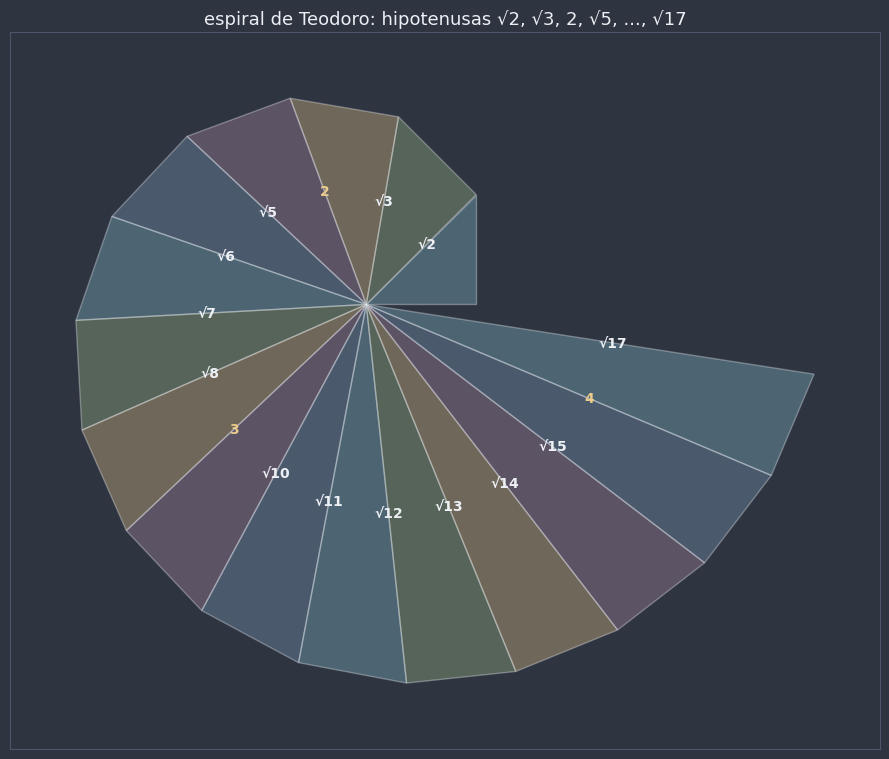

In [7]:
# (a) Cada passo: andar 1 na direção perpendicular a OPk (OPk girado de 90°, dividido pelo tamanho)
pontos_ex6 = [np.array([1.0, 0.0])]
while len(pontos_ex6) < 17:
    x, y = pontos_ex6[-1]
    v = np.array([-y, x]) / math.hypot(x, y)  # perpendicular a OPk, de tamanho 1
    pontos_ex6.append(pontos_ex6[-1] + v)

# (b) e (c) As hipotenusas OP2, ..., OP17 e os seus quadrados
hipotenusas_ex6 = [math.dist((0, 0), P) for P in pontos_ex6[1:]]
quadrados_ex6 = [round(d**2) for d in hipotenusas_ex6]

# (d) √n é irracional quando n não é quadrado perfeito (math.isqrt(n)² ≠ n)
irracionais_ex6 = [n for n in range(2, 18) if math.isqrt(n) ** 2 != n]

print([f"{d:.4f}" for d in hipotenusas_ex6])
print(quadrados_ex6)
print(irracionais_ex6)

# (e) A espiral: cada triângulo O Pk P(k+1), com a hipotenusa OP(k+1) = √(k+1)
fig, ax = plt.subplots(figsize=(9, 9))
fig.patch.set_facecolor(NORD_FUNDO)
O = np.array([0.0, 0.0])
cores = [COR_PONTO, COR_DESTAQUE, COR_AVISO, COR_EXTRA, COR_SECUNDARIA]
for k in range(16):
    P, Q = pontos_ex6[k], pontos_ex6[k + 1]
    ax.add_patch(Polygon([O, P, Q], closed=True, facecolor=cores[k % len(cores)], alpha=0.35, edgecolor=NORD_TEXTO,
                         lw=1))
    racional = math.isqrt(k + 2) ** 2 == k + 2
    ax.text(*(0.55 * Q), f"√{k + 2}" if not racional else f"{math.isqrt(k + 2)}", fontsize=10, ha="center",
            va="center", color=COR_AVISO if racional else NORD_TEXTO, fontweight="bold")
preparar_eixo(ax, pontos_ex6 + [O], margem=0.6)
ax.set_title("espiral de Teodoro: hipotenusas √2, √3, 2, √5, ..., √17", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

Cada triângulo tem catetos $\sqrt{k}$ e $1$, então a hipotenusa nova é $\sqrt{k + 1}$ (Pitágoras). Só três das hipotenusas são inteiras, $\sqrt{4} = 2$, $\sqrt{9} = 3$ e $\sqrt{16} = 4$ (em amarelo na figura); as outras 13 são irracionais e, mesmo assim, foram **construídas** com régua e esquadro, só com segmentos de medida 1. Segundo Platão, o matemático Teodoro de Cirene teria mostrado a irracionalidade de $\sqrt{3}$ até $\sqrt{17}$; a espiral é uma reconstrução moderna dessa ideia, e é curioso que ela "pare" justamente perto de $\sqrt{17}$, quando os triângulos começariam a se sobrepor à primeira volta.

**Exercício 7.** Os quatro "centros" de um triângulo retângulo.

(a) lados a = 11.1803, b = 5, c = 10;  a² = 125 = b² + c² = 125?  True
(b) circuncentro [3.5 6. ],  ponto médio de BC [3.5 6. ]
(c) ortocentro [1. 1.]  (o vértice A é [1. 1.])
(d) baricentro [2.6667 4.3333],  AG/GM = 2.000000
(e) distâncias de I aos lados: [1.90983, 1.90983, 1.90983],  (b + c − a)/2 = 1.909830


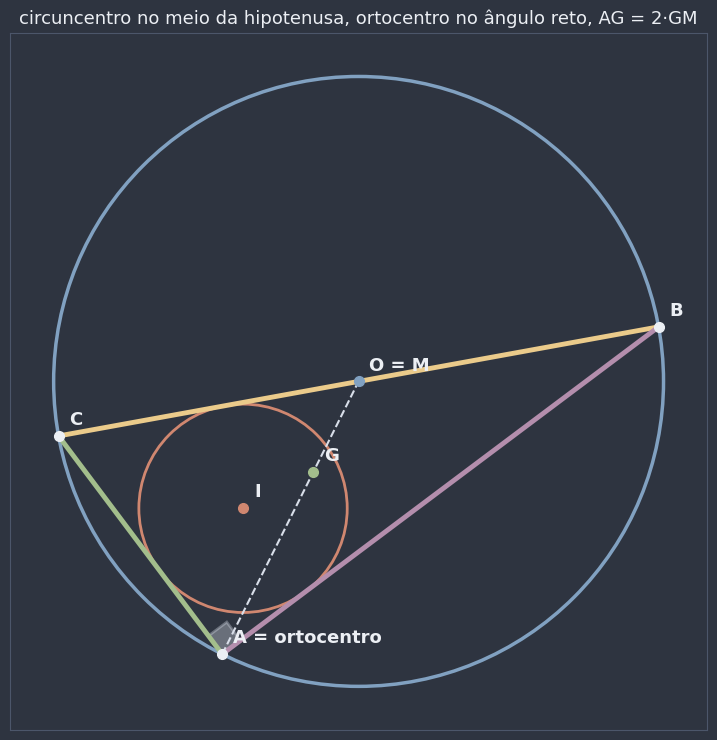

In [8]:
A_ex7, B_ex7, C_ex7 = np.array([1.0, 1.0]), np.array([9.0, 7.0]), np.array([-2.0, 5.0])


def ortocentro_ex7(A, B, C) -> np.ndarray:
    # Altura por A: perpendicular a BC; altura por B: perpendicular a CA. O ortocentro é o cruzamento das duas.
    return cruzamento(A, direcao_de(B, C) + 90, B, direcao_de(C, A) + 90)


# (a) A recíproca de Pitágoras com os três lados: AB = 10, AC = 5, BC = √125
reto_ex7 = eh_retangulo(*lados([A_ex7, B_ex7, C_ex7]))

# (b) Circuncentro e ponto médio da hipotenusa BC
O_ex7 = circuncentro(A_ex7, B_ex7, C_ex7)
M_ex7 = ponto_medio(B_ex7, C_ex7)

# (c) Ortocentro: os catetos são alturas um do outro, então ele cai no vértice do ângulo reto
ortocentro_ex7_valor = ortocentro_ex7(A_ex7, B_ex7, C_ex7)

# (d) Baricentro e a razão em que ele divide a mediana AM
G_ex7 = baricentro(A_ex7, B_ex7, C_ex7)
razao_ex7 = math.dist(A_ex7, G_ex7) / math.dist(G_ex7, M_ex7)

# (e) As distâncias do incentro aos três lados e a fórmula r = (b + c − a)/2
I_ex7 = incentro(A_ex7, B_ex7, C_ex7)
distancias_I_ex7 = tuple(distancia_ponto_reta(I_ex7, P, Q) for P, Q in ((B_ex7, C_ex7), (C_ex7, A_ex7),
                                                                         (A_ex7, B_ex7)))
a, b, c = lados([A_ex7, B_ex7, C_ex7])
r_ex7 = (b + c - a) / 2

print(f"(a) lados a = {a:.4f}, b = {b:g}, c = {c:g};  a² = {a**2:g} = b² + c² = {b**2 + c**2:g}?  {reto_ex7}")
print(f"(b) circuncentro {O_ex7.round(6)},  ponto médio de BC {M_ex7}")
print(f"(c) ortocentro {ortocentro_ex7_valor.round(6)}  (o vértice A é {A_ex7})")
print(f"(d) baricentro {G_ex7.round(4)},  AG/GM = {razao_ex7:.6f}")
print(f"(e) distâncias de I aos lados: {[round(d, 6) for d in distancias_I_ex7]},  (b + c − a)/2 = {r_ex7:.6f}")

fig, ax = plt.subplots(figsize=(10, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
desenhar_circunferencia(ax, O_ex7, a / 2, cor=COR_CIRCULO)
desenhar_circunferencia(ax, I_ex7, r_ex7, cor=COR_ALTURA, largura=2)
for P, Q, cor in ((B_ex7, C_ex7, COR_HIPOTENUSA), (C_ex7, A_ex7, COR_CATETO_B), (A_ex7, B_ex7, COR_CATETO_C)):
    desenhar_segmento(ax, P, Q, cor=cor, largura=3.5)
desenhar_segmento(ax, A_ex7, M_ex7, cor=NORD_TEXTO_SEC, largura=1.5, estilo="--")
desenhar_arco(ax, A_ex7, B_ex7, C_ex7, raio=0.7, cor=NORD_TEXTO_SEC)
for X, nome, cor in ((A_ex7, "A = ortocentro", NORD_TEXTO), (B_ex7, "B", NORD_TEXTO), (C_ex7, "C", NORD_TEXTO),
                     (O_ex7, "O = M", COR_CIRCULO), (G_ex7, "G", COR_DESTAQUE), (I_ex7, "I", COR_ALTURA)):
    desenhar_ponto(ax, X, nome, cor=cor, deslocamento=(0.2, 0.2))
preparar_eixo(ax, [(O_ex7[0] - a / 2, O_ex7[1] - a / 2), (O_ex7[0] + a / 2, O_ex7[1] + a / 2)], margem=0.8)
ax.set_title("circuncentro no meio da hipotenusa, ortocentro no ângulo reto, AG = 2·GM", color=NORD_TEXTO,
             fontsize=13)
plt.tight_layout()
plt.show()

Os quatro resultados juntos fecham [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) no caso retângulo: o **circuncentro** é o ponto médio da hipotenusa ($R = \frac{a}{2}$), o **ortocentro** é o vértice do ângulo reto, o **baricentro** fica a $\frac{2}{3}$ do caminho de $A$ até $M$ na mediana (que mede $\frac{a}{2}$, então $AG = \frac{a}{3}$) e o **incentro** está à distância $r = \frac{b + c - a}{2}$ dos três lados. Repare que $O$, $G$ e o ortocentro $A$ estão alinhados sobre a mediana $\overline{AM}$: é a **reta de Euler**, que no triângulo retângulo é justamente a mediana relativa à hipotenusa.